# Ridgeline Plot (Joy Plot)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Stacks partially overlapping density curves for many groups, one per row. Shifts in the distribution across groups or time read as a compact landscape.

## When to use

- Compare distributions across many groups (5–20), especially ordered ones like months or years
- Show how a distribution shifts over time

## Avoid when

- There are only two or three groups (overlay KDEs instead)
- Precise reading of density values is needed

## Alternatives

- Violin plot
- Small-multiple histograms
- Box plots

## Design tips

- Order the rows meaningfully (time, or by median)
- Use one hue or a sequential ramp mapped to the order

## Example

Daily maximum temperature distribution for each month of the year (synthetic city).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(13)
groups = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
means = 15 + 11 * np.sin((np.arange(12) - 3.5) / 12 * 2 * np.pi)
df = pd.concat([pd.DataFrame({"group": m, "value": rng.normal(mu, 3 + abs(mu - 15) * 0.1, 31)})
                for m, mu in zip(groups, means)], ignore_index=True)
labels = dict(x="Daily maximum temperature (°C)", title="Daily highs by month")
df.groupby("group", sort=False)["value"].mean().round(1)

group
Jan     5.8
Feb     5.0
Mar     6.5
Apr    12.2
May    18.3
Jun    23.4
Jul    24.7
Aug    26.1
Sep    21.8
Oct    17.4
Nov    11.4
Dec     8.1
Name: value, dtype: float64

### Plot

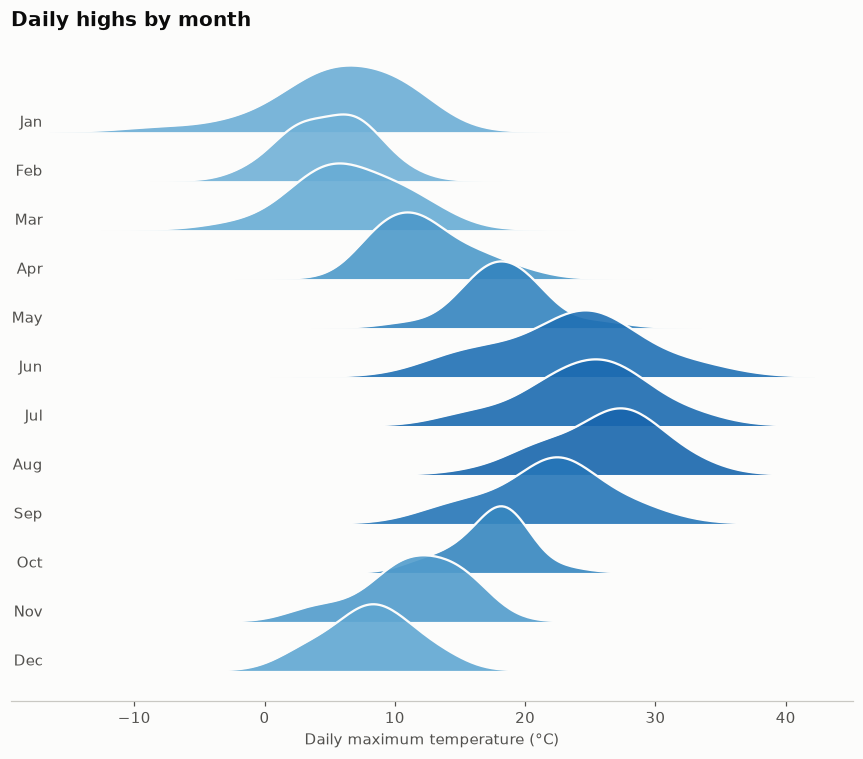

In [3]:
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(8, 7))
pad = np.ptp(df["value"]) * 0.2
xs = np.linspace(df["value"].min() - pad, df["value"].max() + pad, 300)
cmap = plt.get_cmap(SEQ_CMAP)
spacing = 1.0
for i, m in enumerate(groups):
    vals = df.loc[df["group"] == m, "value"]
    dens = gaussian_kde(vals, bw_method=0.6)(xs)
    dens = dens / dens.max() * 1.35
    base = (len(groups) - 1 - i) * spacing
    color = cmap(0.3 + 0.6 * (vals.mean() - df["value"].min()) / np.ptp(df["value"]))
    ax.fill_between(xs, base, base + dens, color=color, alpha=0.9, zorder=i, linewidth=0)
    ax.plot(xs, base + dens, color="#fcfcfb", linewidth=1.5, zorder=i)
    ax.text(xs[0] - pad * 0.06, base + 0.1, m, fontsize=9.5, color="#52514e", ha="right")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_xlabel(labels["x"])
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

## How to read it

Each ridge is one month's distribution of daily highs, and darker color means warmer. The peaks move right towards July–August and back left by December.

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder life expectancy, GDP and population 1952–2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
import plotly.express as px
gm = px.data.gapminder()
groups = [str(y) for y in sorted(gm["year"].unique())]
df = pd.DataFrame({"group": gm["year"].astype(str), "value": gm["lifeExp"]})
labels = dict(x="Life expectancy at birth (years), 142 countries",
              title="The world's life-expectancy distribution, 1952–2007")
df.groupby("group", sort=False)["value"].mean().round(1)

group
1952    49.1
1957    51.5
1962    53.6
1967    55.7
1972    57.6
1977    59.6
1982    61.5
1987    63.2
1992    64.2
1997    65.0
2002    65.7
2007    67.0
Name: value, dtype: float64

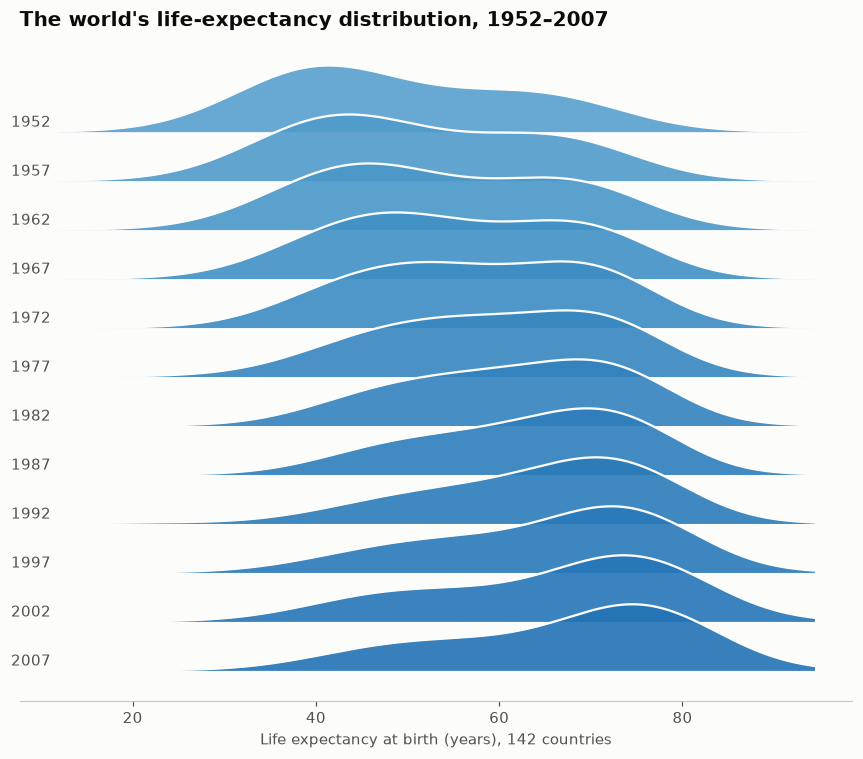

In [5]:
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(8, 7))
pad = np.ptp(df["value"]) * 0.2
xs = np.linspace(df["value"].min() - pad, df["value"].max() + pad, 300)
cmap = plt.get_cmap(SEQ_CMAP)
spacing = 1.0
for i, m in enumerate(groups):
    vals = df.loc[df["group"] == m, "value"]
    dens = gaussian_kde(vals, bw_method=0.6)(xs)
    dens = dens / dens.max() * 1.35
    base = (len(groups) - 1 - i) * spacing
    color = cmap(0.3 + 0.6 * (vals.mean() - df["value"].min()) / np.ptp(df["value"]))
    ax.fill_between(xs, base, base + dens, color=color, alpha=0.9, zorder=i, linewidth=0)
    ax.plot(xs, base + dens, color="#fcfcfb", linewidth=1.5, zorder=i)
    ax.text(xs[0] - pad * 0.06, base + 0.1, m, fontsize=9.5, color="#52514e", ha="right")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_xlabel(labels["x"])
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

---
Standalone script: [`ridgeline.py`](ridgeline.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)